In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from time import perf_counter

In [23]:
rng = np.random.default_rng(42)
def draw_ellipse(ax, mean, cov, color):
    """Draw the 1- and 2-standard-deviation contours of N(mean, cov)."""
    vals, vecs = np.linalg.eigh(cov) # eigenvalues in ascending order
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    for n_std in (1, 2):
        width, height = 2 * n_std * np.sqrt(vals[::-1])
        ax.add_patch(Ellipse(mean, width, height, angle=angle, fill=False, edgecolor=color, linewidth=1.5))

1. Data generation (2 Marks)  
(a) Define three 2-dimensional Gaussian distributions with some overlap. Choose your own mixing weights π<sub>k</sub>, means μ<sub>k</sub> and covariance matrices Σ<sub>k</sub> (k = 1,2,3) such that: 
- the weights are not all equal, each weight is at least 0.15, the weights sum to 1, and each has at most two decimal places (for example, 0.45);
- at least one covariance matrix has a non-zero off-diagonal entry, so that its contours are tilted;
- every covariance matrix is symmetric and positive definite (check that both eigenvalues returned by np.linalg.eigvalsh are positive);
- the components overlap partly but can still be told apart by eye. As a guide, keep the means about 3 to 5 units apart and the diagonal entries of each Σ<sub>k</sub> between 0.5 and 2.  
Present your chosen parameters. These are the true parameters for the rest of the lab.

In [24]:
true_wt = np.array([0.39,0.33,0.28])
true_mean = np.array([[5,9],[8,13],[6,11]])
true_cov = np.array([[[1.00,0.30],
                      [0.30,1.00]],
                     [[0.84,0.62],
                      [0.62,0.84]],
                     [[0.93,0.18],
                      [0.18,0.93]]])

for i in range(3):
    assert(np.linalg.eigvalsh(true_cov[i]).all() > 0)

for k in range(3):
    print(f"Mean of cluster {k} is {np.mean(true_mean[k])}")
    print(f"Weight of cluster {k} is {true_wt[k]}")
    print(f"Covariance of cluster {k} is {np.round(true_cov[k],2)}")
    print()

Mean of cluster 0 is 7.0
Weight of cluster 0 is 0.39
Covariance of cluster 0 is [[1.  0.3]
 [0.3 1. ]]

Mean of cluster 1 is 10.5
Weight of cluster 1 is 0.33
Covariance of cluster 1 is [[0.84 0.62]
 [0.62 0.84]]

Mean of cluster 2 is 8.5
Weight of cluster 2 is 0.28
Covariance of cluster 2 is [[0.93 0.18]
 [0.18 0.93]]




(b) Using rng.multivariate normal, draw 900 π<sub>k</sub> points from component k, for k = 1,2,3 in that order. Stack them into a data matrix X of shape 900 ×2 and keep a vector y of the true component labels. Do not shuffle the data.

In [25]:
cluster = {}
X = []
y = []
for k in range(3):
    cluster[k] = rng.multivariate_normal(true_mean[k], true_cov[k], size=int(900*true_wt[k]))
    X.append(cluster[k])
    y.append(np.ones((int(900*true_wt[k]),1))*k)

X = np.vstack(X)
y = np.vstack(y)

print(cluster)
print(X)
print(y)

{0: array([[ 5.36959213,  8.13906634],
       [ 3.83852131,  8.95141249],
       [ 7.34335464,  9.80259507],
       [ 5.08402341,  8.70984013],
       [ 5.51821312,  8.50887793],
       [ 3.83085877,  8.7511546 ],
       [ 4.27987946,  9.61364924],
       [ 5.1314462 ,  8.11471764],
       [ 5.26998621,  8.13542102],
       [ 4.32130729,  8.26223416],
       [ 5.55188415,  8.74619745],
       [ 4.10577654,  7.92293479],
       [ 5.55365395,  9.13700391],
       [ 4.35463899,  8.78703824],
       [ 4.41236719,  8.92212147],
       [ 3.51378687,  7.03291014],
       [ 5.89441773,  8.93154885],
       [ 3.8354725 ,  9.17129053],
       [ 5.58891065,  8.5948241 ],
       [ 5.27982212, 10.04961389],
       [ 4.07943493,  8.72210373],
       [ 5.39920259,  9.67389957],
       [ 4.77654697,  9.03530281],
       [ 4.16515075,  8.42971257],
       [ 4.41266207,  8.4926227 ],
       [ 4.39342934,  9.14037964],
       [ 6.36391662,  9.98567654],
       [ 5.75719179,  9.00126133],
       [ 4.33740

(c) Plot all 900 points, using a different colour for each true component, and draw the contours of each true Gaussian using draw ellipse. The overlap between the components should be visible; if the components do not overlap at all, or overlap so much that they cannot be told apart, adjust your parameters in (a).

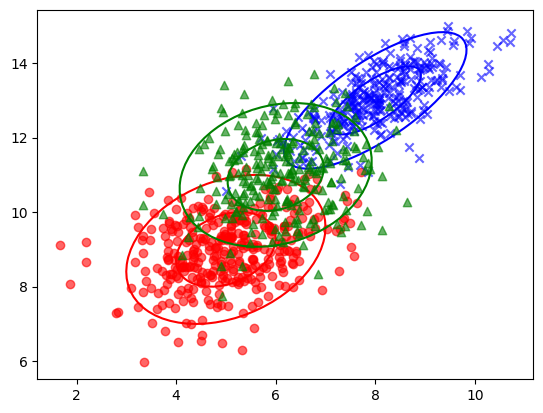

In [26]:
fig, ax = plt.subplots()
colors = ["red", "blue", "green"]
markers = ["o", "x", "^"]
for k in range(3):
    ax.scatter(cluster[k][:,0], cluster[k][:,1], c=colors[k], alpha = 0.6, marker=markers[k])
    draw_ellipse(ax, true_mean[k], true_cov[k], color=colors[k])
plt.show()

2. EM from scratch (4 Marks)  
(a) Write a function gaussian pdf(X, mu, Sigma) that returns the multivariate Gaussian density N(x<sub>n</sub>|μ,Σ) for every row x<sub>n</sub> of X. Compute it for all rows at once using numpy array operations rather than a Python loop over the points; this keeps Part 4 fast.

In [27]:
def gaussian_pdf(x, mu, sigma):
    inv_sigma = np.linalg.inv(sigma)
    det_sigma = np.linalg.det(sigma)
    exponent = -0.5 * (np.dot(x - mu, np.dot(inv_sigma, (x - mu).T)))
    return np.exp(exponent) / (2 * np.pi * np.sqrt(det_sigma))

(b) Write a function with the following signature that fits a K-component GMM using EM:
One iteration consists of one E-step (compute the responsibilities γnk) followed by one M-step (update πk, μkand Σk). The function must:
- Initialise the means by choosing K distinct data points as follows:
rng = np.random.default_rng(seed)
idx = rng.choice(N, K, replace=False) # initial means are X[idx]
Set every Σkto the covariance of the full dataset (np.cov(X.T)), and set every
πk= 1/K.
- In the M-step, add 1e-6 * np.eye(2) to each updated covariance matrix so that it stays invertible.
- Compute the log-likelihood ℓ = ∑nlog ∑kπkN(xn|μk,Σk) after initialisation and after every iteration.
- Stop when the change in log-likelihood between two consecutive iterations is less than tol, or after max iter iterations.
- Return the final parameters, the final responsibilities, the list of log-likelihood values, and a copy of the parameters at iterations 0,5,10,... and at the final iteration
(needed for Part 2(d)).

In [28]:
def em_gmm(X, K=3, seed=42, tol=1e-6, max_iter=500):
    N, D = X.shape
    
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), K, replace=False) # initial means are X[idx]
    mean = X[idx].copy()
    wt = [1/K for _ in range(K)]
    cov = [np.cov(X.T) for _ in range(K)]
    
    L_total = 0
    for n in range(N):
        L = 0
        for k in range(K):
            L += wt[k] * gaussian_pdf(X[n], mean[k], cov[k])
        L_total += np.log(L)
    LL = [L_total]
    
    r = np.zeros((N, K))
    every5 = [(np.array(wt).copy(), mean.copy(), np.array(cov).copy(), r.copy(), LL[0])]
    
    for i in range(1,max_iter+1):
        # === E-step ===
        for n in range(N):
            row_sum = 0
            for k in range(K):
                row_sum += wt[k] * gaussian_pdf(X[n], mean[k], cov[k])
            
            for k in range(K):
                r[n, k] = wt[k] * gaussian_pdf(X[n], mean[k], cov[k]) / row_sum
                
        # === M-step ===
        for k in range(K):
            r_sum = np.sum(r[:, k])
            
            wt[k] = r_sum / N
            mean[k] = np.dot(r[:, k], X) / r_sum
            cov[k] = np.einsum('n, ni, nj -> ij', r[:, k], X - mean[k], X - mean[k]) / r_sum
            
            cov[k] = cov[k] + tol * np.eye(D)
        
        # === Calculate Log-Likelihood for this iteration ===
        L_total = 0
        for n in range(N):
            L = 0
            for k in range(K):
                L += wt[k] * gaussian_pdf(X[n], mean[k], cov[k])
            L_total += np.log(L)
        LL.append(L_total)
        
        if i % 5 == 0:
            every5.append((np.array(wt).copy(), mean.copy(), np.array(cov).copy(), r.copy(), LL[i]))
        
        if np.abs(LL[i] - LL[i-1]) < tol:
            break

    return wt, mean, cov, r, LL, every5

(c) Run em gmm on X with K = 3 and seed = 42. Report the number of iterations taken to converge and the final log-likelihood. Plot the log-likelihood against the iteration number, and verify that it never decreases.

Number of iterations: 501
Final Log-likelihood: -2998.568616015415


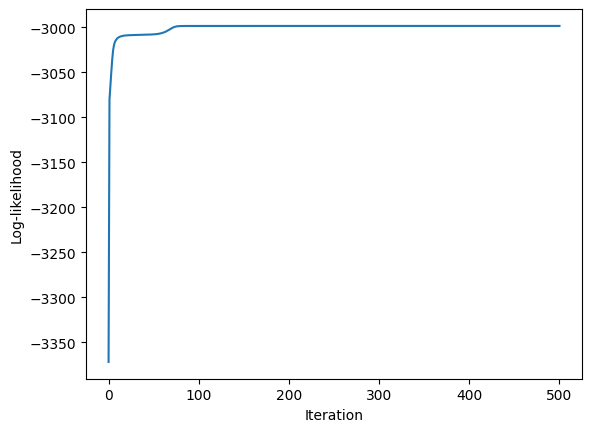

In [29]:
wt, mean, cov, r, LL, every5 = em_gmm(X, K=3, seed=42)

print(f"Number of iterations: {len(LL)}")
print(f"Final Log-likelihood: {LL[-1]}")

plt.plot(range(len(LL)), LL)
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.show()


(d) Show the progress of EM in a grid of subplots: one subplot for the initialisation (iteration 0), one after every 5 iterations (5, 10, 15, . . . ), and one for the final iteration. In each subplot, colour every point by its most responsible component (argmax<sub>k</sub>γ<sub>nk</sub>, computed from the current parameters), draw the current components with draw ellipse, and show the iteration number and log-likelihood in the title.




In [38]:
final_iter = len(LL) - 1
if final_iter % 5 != 0:
    every5.append((np.array(wt).copy(), mean.copy(), np.array(cov).copy(), r.copy(), LL[-1]))

num_plots = len(every5)
ncols = 3
nrows = int(np.ceil(num_plots / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = axes.flatten()

cluster_colors = ['red', 'blue', 'green', 'purple', 'orange', 'cyan']

for idx, snapshot in enumerate(every5):
    ax = axes[idx]
    snapshot_wt, snapshot_mean, snapshot_cov, snapshot_r, snapshot_ll = snapshot
    
    if idx == 0:
        title_str = "Iteration 0 (Init)"
    elif idx == num_plots - 1:
        title_str = f"Iteration {final_iter} (Final)"
    else:
        title_str = f"Iteration {idx * 5}"

    if np.all(snapshot_r == 0):
        labels = np.zeros(len(X), dtype=int)
    else:
        labels = np.argmax(snapshot_r, axis=1)
        
    point_colors = [cluster_colors[k % len(cluster_colors)] for k in labels]
    ax.scatter(X[:, 0], X[:, 1], c=point_colors, s=15, alpha=0.5)

    K = len(snapshot_mean)
    for k in range(K):
        draw_ellipse(ax, snapshot_mean[k], snapshot_cov[k], color=cluster_colors[k % len(cluster_colors)])
        ax.scatter(snapshot_mean[k, 0], snapshot_mean[k, 1], c='black', marker='x', s=40, zorder=10)

    ax.set_title(f"{title_str}\nLL: {snapshot_ll:.4f}", fontsize=10)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(True, linestyle=':', alpha=0.5)
    
for empty_idx in range(num_plots, len(axes)):
    fig.delaxes(axes[empty_idx])

plt.tight_layout()
plt.show()

3. Comparison with the true parameters (2 Marks)  
(a) The order of the components learned by EM is arbitrary (“component 1” of your model need not correspond to true component 1). Match the learned components to the true ones by trying all 3! = 6 orderings (itertools.permutations) and choosing the ordering that minimises the total Euclidean distance between the learned and true means. Use this matching for the rest of Part 3.

In [31]:
import itertools

learned_mean = np.array(mean)
K = len(true_mean)

best_permutation = None
min_total_distance = float('inf')

for perm in itertools.permutations(range(K)):
    current_distance = 0.0
    for true_idx, learned_idx in enumerate(perm):
        diff = true_mean[true_idx] - learned_mean[learned_idx]
        current_distance += np.sqrt(np.sum(diff ** 2))
        
    if current_distance < min_total_distance:
        min_total_distance = current_distance
        best_permutation = perm

matched_mean = learned_mean[list(best_permutation)]
matched_wt = np.array(wt)[list(best_permutation)]
matched_cov = np.array(cov)[list(best_permutation)]

if 'r' in locals() and r.shape[1] == K:
    matched_r = r[:, list(best_permutation)]
else:
    matched_r = None

print(f"Optimal permutation sequence mapping: {best_permutation}")
print(f"Minimum total Euclidean distance between means: {min_total_distance:.6f}\n")

for i in range(K):
    print(f"True Component {i+1} Mean:    {true_mean[i]}")
    print(f"Matched Learned Component {i+1} Mean: {matched_mean[i]}")
    print("-" * 45)

Optimal permutation sequence mapping: (1, 0, 2)
Minimum total Euclidean distance between means: 0.790359

True Component 1 Mean:    [5 9]
Matched Learned Component 1 Mean: [5.14374189 9.17785103]
---------------------------------------------
True Component 2 Mean:    [ 8 13]
Matched Learned Component 2 Mean: [ 8.03784727 13.08318442]
---------------------------------------------
True Component 3 Mean:    [ 6 11]
Matched Learned Component 3 Mean: [ 6.30452865 11.35838284]
---------------------------------------------


(b) Present a table comparing the true and estimated π<sub>k</sub>, μ<sub>k</sub> and Σ<sub>k</sub> for each component. Which component is estimated least accurately? Suggest a reason.

In [32]:
t_wt = np.array(true_wt)
t_mu = np.array(true_mean)
t_sig = np.array(true_cov)

m_wt = np.array(matched_wt)
m_mu = np.array(matched_mean)
m_sig = np.array(matched_cov)

wt_errors = np.abs(t_wt - m_wt)
mu_errors = np.sqrt(np.sum((t_mu - m_mu)**2, axis=1))
cov_errors = np.array([np.linalg.norm(t_sig[k] - m_sig[k], ord='fro') for k in range(len(t_wt))])

data = []
for k in range(len(t_wt)):
    data.append({
        "Component": f"Component {k+1}",
        "True π": f"{t_wt[k]:.3f}",
        "Est π": f"{m_wt[k]:.3f}",
        "π Error": f"{wt_errors[k]:.4f}",
        "True μ": f"[{t_mu[k][0]:.2f}, {t_mu[k][1]:.2f}]",
        "Est μ": f"[{m_mu[k][0]:.2f}, {m_mu[k][1]:.2f}]",
        "μ Error": f"{mu_errors[k]:.4f}",
        "Σ Error (Frobenius)": f"{cov_errors[k]:.4f}"
    })

df_comparison = pd.DataFrame(data)
display(df_comparison)

# Print diagnostic metrics to pinpoint the issue
worst_mu_k = np.argmax(mu_errors)
worst_cov_k = np.argmax(cov_errors)
print(f"\nHighest Mean Error: Component {worst_mu_k + 1} ({mu_errors[worst_mu_k]:.4f})")
print(f"Highest Covariance Error: Component {worst_cov_k + 1} ({cov_errors[worst_cov_k]:.4f})")

,Component,True π,Est π,π Error,True μ,Est μ,μ Error,Σ Error (Frobenius)
0,Component 1,0.390,0.468,0.0778,"[5.00, 9.00]","[5.14, 9.18]",0.2287,0.1849
1,Component 2,0.330,0.328,0.0016,"[8.00, 13.00]","[8.04, 13.08]",0.0914,0.2646
2,Component 3,0.280,0.204,0.0762,"[6.00, 11.00]","[6.30, 11.36]",0.4703,0.4897



Highest Mean Error: Component 3 (0.4703)
Highest Covariance Error: Component 3 (0.4897)


Component 3 is estimated least accurately. This may be because component 3 is between components 1 and 2 and thus has significant overlap with them.

(c) Redo the plot of Part 1(c) using the learned model: colour each point by its most responsible (matched) component and draw the learned contours. Place it side by side with the plot of Part 1(c), and report the percentage of points whose assigned component equals their true component.

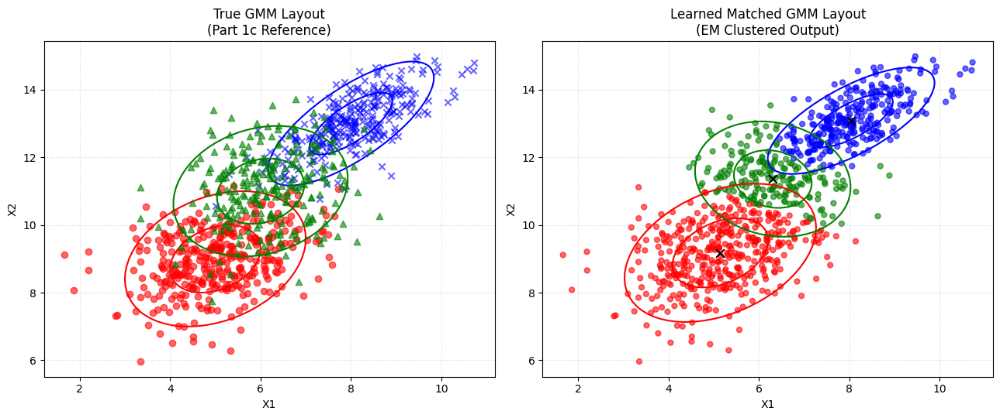

=== Component Assignment Metrics ===
Total matched data points: 749 / 900
Percentage of points correctly assigned to their true component: 83.22%


In [39]:
true_labels = np.concatenate([np.full(len(cluster[k]), k) for k in range(3)])

predicted_labels = np.argmax(matched_r, axis=1)

correct_matches = np.sum(true_labels == predicted_labels)
total_points = len(true_labels)
accuracy_percentage = (correct_matches / total_points) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
colors = ["red", "blue", "green"]
markers = ["o", "x", "^"]

for k in range(3):
    ax1.scatter(cluster[k][:, 0], cluster[k][:, 1], c=colors[k], alpha=0.6, marker=markers[k])
    draw_ellipse(ax1, true_mean[k], true_cov[k], color=colors[k])
ax1.set_title("True GMM Layout\n(Part 1c Reference)", fontsize=12)
ax1.set_xlabel("X1")
ax1.set_ylabel("X2")
ax1.grid(True, linestyle=':', alpha=0.5)

point_colors = [colors[k] for k in predicted_labels]
ax2.scatter(X[:, 0], X[:, 1], c=point_colors, alpha=0.6, s=25)

for k in range(3):
    draw_ellipse(ax2, matched_mean[k], matched_cov[k], color=colors[k])
    ax2.scatter(matched_mean[k, 0], matched_mean[k, 1], c='black', marker='x', s=60, zorder=10)

ax2.set_title("Learned Matched GMM Layout\n(EM Clustered Output)", fontsize=12)
ax2.set_xlabel("X1")
ax2.set_ylabel("X2")
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"=== Component Assignment Metrics ===")
print(f"Total matched data points: {correct_matches} / {total_points}")
print(f"Percentage of points correctly assigned to their true component: {accuracy_percentage:.2f}%")


4. Effect of initialisation (2 Marks)  
(a) Run em gmm with K = 3 for seed = 0,1,2,3,4. Report the number of iterations and the final log-likelihood for each seed in a table. Do all runs reach the same solution? If any run ends with a lower log-likelihood, explain what has happened; if all runs agree, explain why EM can still end at a worse solution in general. Which run would you keep, and why?

In [40]:
seeds = [0, 1, 2, 3, 4]
results = []

for s in seeds:
    _, _, _, _, LL, _ = em_gmm(X, K=3, seed=s, tol=1e-6, max_iter=500)
    
    num_iterations = len(LL) - 1
    final_ll = LL[-1]
    
    results.append({
        "Seed": s,
        "Iterations to Converge": num_iterations,
        "Final Log-Likelihood": round(final_ll, 4)
    })

df_results = pd.DataFrame(results)
display(df_results)


,Seed,Iterations to Converge,Final Log-Likelihood
0,0,500,-2998.6187
1,1,500,-2998.6079
2,2,500,-2998.5688
3,3,500,-2998.5686
4,4,489,-2998.5686


All runs give us similar results. EM can still end at a worse solution in general because EM is a local optimization method and can get stuck at a local maximum. Also, if the initial clusters are not well separated, EM will adjust locally and get stuck.

(b) Summarise your observations from this lab in 4–6 sentences.

This lab taught us how to implement a GMM model and also demonstrated the effects of label switching and the outputs when using different seeds. We used Expectation Maximization (EM) algorithm to train the model.